In [51]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_gaussian_quantiles
import matplotlib.pyplot as plt

In [56]:
rand = 42
sample_amount = 40_0
feature_amount = 20

In [57]:
#dataset 1 (8 blobs)

X, cluster_id = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=8, cluster_std=1.2, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [26]:
#dataset 2 (1 cluster with correlated features)

mean = np.zeros(feature_amount)
cov = np.random.default_rng(rand).uniform(-0.5, 0.5, size=(feature_amount, feature_amount))
cov = cov @ cov.T
X = np.random.default_rng(rand).multivariate_normal(mean, cov, size=sample_amount)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [28]:
#dataset 3 (nested/ non-linear structure)

X, y = make_gaussian_quantiles(n_samples=sample_amount, n_features=feature_amount, n_classes=3, random_state=rand)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [54]:
#1 | extreme        | push feature values far outside range
#2 | gaussian       | add jitter to feature values
#3 | shuffle        | swap feature values with other row's
#4 | uniform_random | replace feature values with values from data range (ignores correlation)

def inject_noise(df, noise_frac=0.05, method=1, n_features_affected=None, seed=rand):

    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    mask = np.zeros(n, dtype=bool)
    mask[df.index.get_indexer(noise_idx)] = True

    for row_id in noise_idx:
        if n_features_affected is None:
            cols = cols_all
        else:
            cols = rng.choice(cols_all, size=n_features_affected, replace=False)

        for col in cols:
            std = df[col].std()

            match method:
                case 1:
                    direction = rng.choice([-1, 1])
                    magnitude = rng.uniform(6, 12)
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * std * magnitude

                case 2:
                    noisy.loc[row_id, col] = df.loc[row_id, col] + rng.normal(0, std * 3)

                case 3:
                    donor_id = rng.choice(df.index)
                    noisy.loc[row_id, col] = df.loc[donor_id, col]

                case 4:
                    lo, hi = df[col].min(), df[col].max()
                    noisy.loc[row_id, col] = rng.uniform(lo, hi)

                case _:
                    raise ValueError(f"Unknown method: {method}")

    return noisy, mask 

In [62]:
noisy_df, true_mask = inject_noise(df, noise_frac=0.1, method=4)

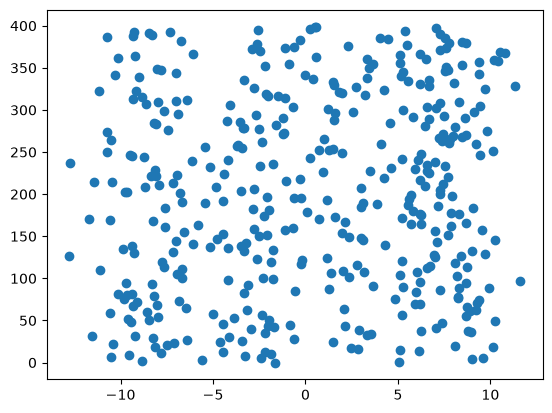

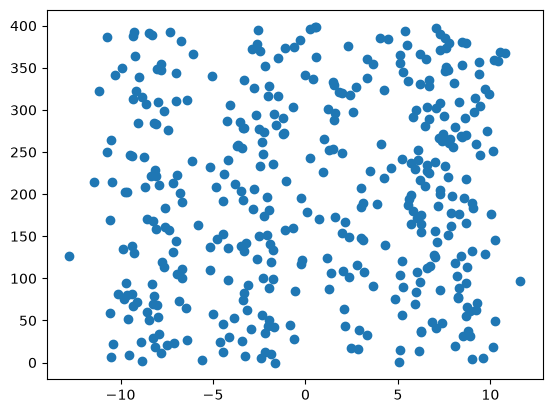

In [65]:
plt.scatter(noisy_df.iloc[:, 0], df.index)
plt.show()

plt.scatter(df.iloc[:, 0], df.index)
plt.show()